# TP 1 : Détection de Spam avec Naive Bayes
## Objectif
Construire un modèle de détection de spam en utilisant un classificateur bayésien (Naive Bayes).

In [9]:
# Imports nécessaires
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline

## 1. Chargement et analyse des données# Charger le dataset spam (adapter le chemin si nécessaire)


In [10]:
# Exemple pour Colab : data = pd.read_csv('/content/drive/MyDrive/ADA_M201_spam/spam.csv')
data = pd.read_csv('spam.csv', encoding='latin-1')

# Afficher les premières lignes
print(data.head())

# Informations générales
print(data.info())
print(data.isna().sum())

  Category                                            Message
0      ham  Go until jurong point, crazy.. Available only ...
1      ham                      Ok lar... Joking wif u oni...
2     spam  Free entry in 2 a wkly comp to win FA Cup fina...
3      ham  U dun say so early hor... U c already then say...
4      ham  Nah I don't think he goes to usf, he lives aro...
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Category  5572 non-null   object
 1   Message   5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB
None
Category    0
Message     0
dtype: int64


## 2. Prétraitement des données

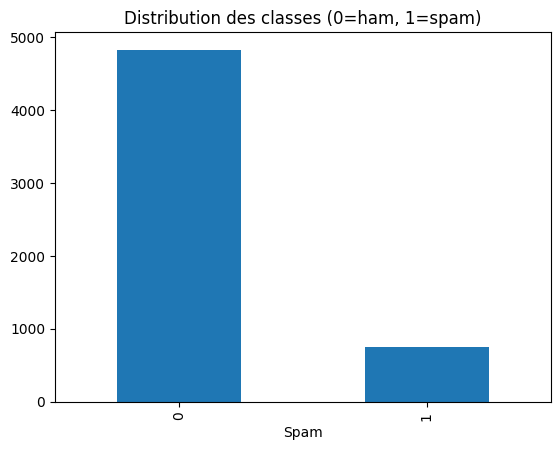

In [11]:
# Créer une nouvelle colonne binaire 'Spam'
data['Spam'] = data['Category'].apply(lambda x: 1 if x == 'spam' else 0)

# Diviser en train/test
X_train, X_test, y_train, y_test = train_test_split(
    data['Message'], data['Spam'], test_size=0.25, random_state=42
)

# Vérifier la distribution
data['Spam'].value_counts().plot(kind='bar')
plt.title("Distribution des classes (0=ham, 1=spam)")
plt.show()

## 3. Construction et entraînement du modèle

In [12]:
# Pipeline avec Count Vectorizer et MultinomialNB
clf = Pipeline([
    ('vectorizer', CountVectorizer()),
    ('nb', MultinomialNB())
               ])

# Entraînement du modèle
clf.fit(X_train, y_train)

# Évaluation du modèle
accuracy = clf.score(X_test, y_test)
print("Précision du modèle:", accuracy)

Précision du modèle: 0.990667623833453


## 4. Tester le modèle avec de nouveaux emails

In [13]:
emails = [
    "Sounds great! Are you home now?",
    "Will u meet ur dream soon? Is ur career off 2 a flying start? 2 find out free, txt HORO followed by ur star sign",
    "subscribe now for free",
    "Hi, can you send me the report of last sprint",
    "Testons maintenant cette phrase française",
    "Students of AI will be amazed with this application of Naive Bayesian, Best Regards"
]

predictions = clf.predict(emails)

for mail, pred in zip(emails, predictions):
    print(f"[{'SPAM' if pred==1 else 'HAM'}] {mail}")

[HAM] Sounds great! Are you home now?
[SPAM] Will u meet ur dream soon? Is ur career off 2 a flying start? 2 find out free, txt HORO followed by ur star sign
[SPAM] subscribe now for free
[HAM] Hi, can you send me the report of last sprint
[HAM] Testons maintenant cette phrase française
[HAM] Students of AI will be amazed with this application of Naive Bayesian, Best Regards
